<a href="https://colab.research.google.com/github/dinathsv/Customer-Segmentation-for-an-Online-Retailer-K-Means-versus-DBSCAN-ML/blob/main/E2340013_Machine_Learning_Assignment_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
!pip install -q openpyxl

import warnings, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
RANDOM_STATE = 42

In [29]:
from google.colab import files
import zipfile, os

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail (1).xlsx


In [30]:
xlsx_file = [f for f in os.listdir(".") if f.lower().endswith(".xlsx")][0]
print("Loading:", xlsx_file)

raw = pd.read_excel(xlsx_file)
raw.to_pickle("raw.pkl")
print(raw.shape)
raw.head()

Loading: Online Retail.xlsx
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [31]:
df = raw.copy()
print("Records:", df.shape[0], "| Variables:", df.shape[1])
print("\nData types:\n", df.dtypes)
print("\nDate range:", df.InvoiceDate.min(), "->", df.InvoiceDate.max())
print("Unique customers:", df.CustomerID.nunique())
print("Unique invoices :", df.InvoiceNo.nunique())
print("Unique products :", df.StockCode.nunique())
print("Countries       :", df.Country.nunique())

Records: 541909 | Variables: 8

Data types:
 InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Unique customers: 4372
Unique invoices : 25900
Unique products : 4070
Countries       : 38


In [32]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = missing["missing"] / len(df) * 100
display(missing)

print("Exact duplicate rows:", df.duplicated().sum())
print("Cancelled invoices (InvoiceNo starts with 'C'):",
      df.InvoiceNo.astype(str).str.startswith("C").sum())
print("Rows with Quantity <= 0 :", (df.Quantity <= 0).sum())
print("Rows with UnitPrice <= 0:", (df.UnitPrice <= 0).sum())

display(df[["Quantity", "UnitPrice"]].describe().T)
display(df.describe(include="object").T)

,missing,pct
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Exact duplicate rows: 5268
Cancelled invoices (InvoiceNo starts with 'C'): 9288
Rows with Quantity <= 0 : 10624
Rows with UnitPrice <= 0: 2517


,count,mean,std,min,25%,50%,75%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"


,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
Country,541909,38,United Kingdom,495478


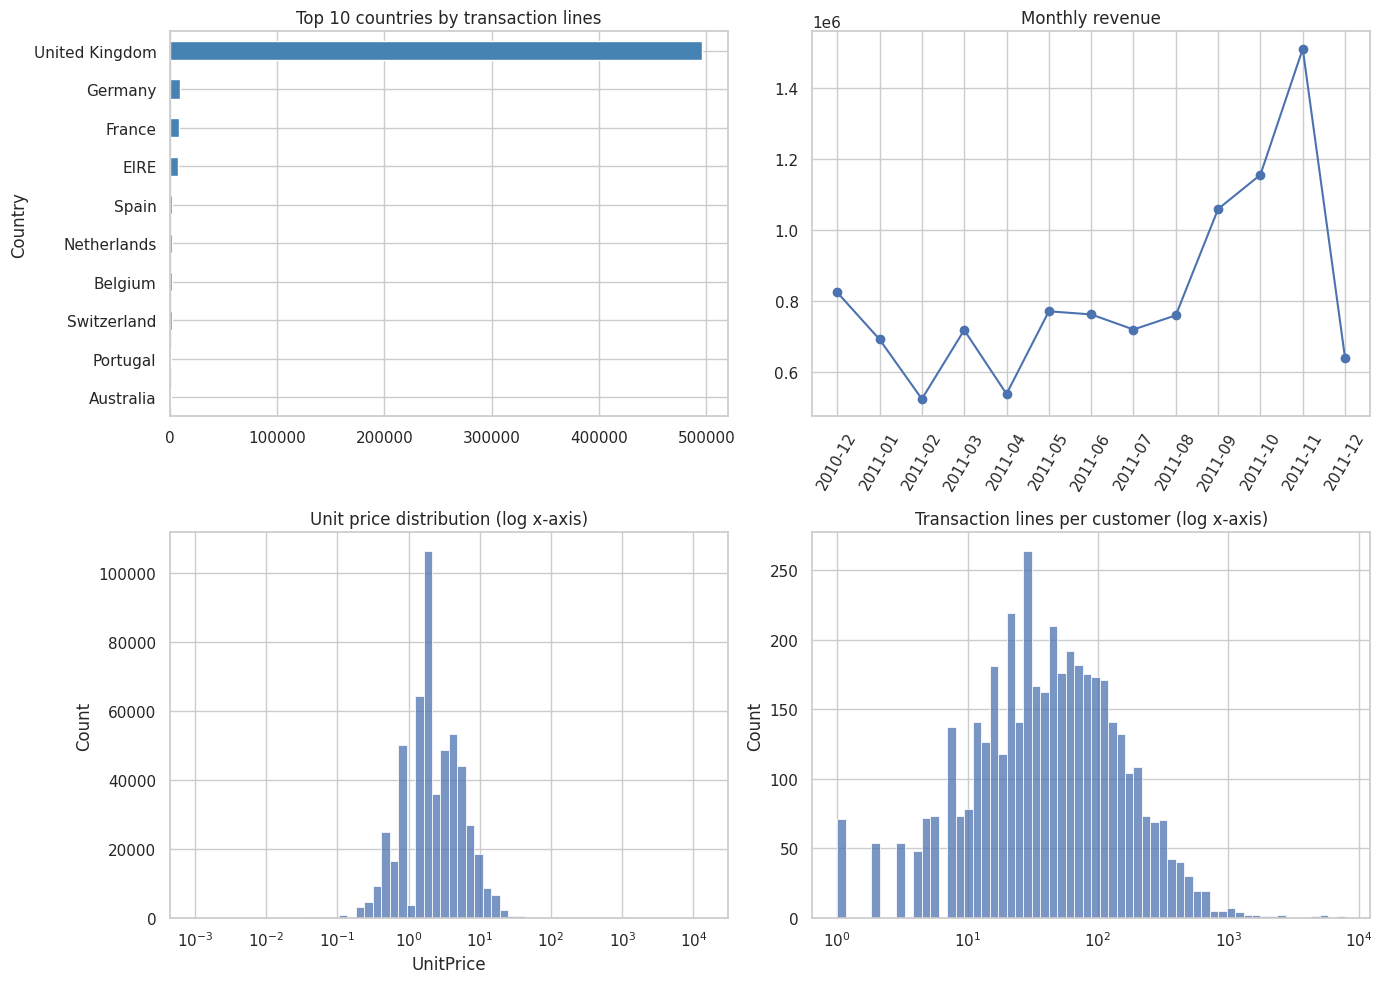

In [33]:
tmp = df[(df.Quantity > 0) & (df.UnitPrice > 0)].copy()
tmp["Revenue"] = tmp.Quantity * tmp.UnitPrice

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Top countries by number of rows
df.Country.value_counts().head(10).plot.barh(ax=ax[0, 0], color="steelblue")
ax[0, 0].invert_yaxis()
ax[0, 0].set_title("Top 10 countries by transaction lines")

# 2. Monthly revenue
monthly = tmp.groupby(tmp.InvoiceDate.dt.to_period("M")).Revenue.sum()
ax[0, 1].plot(monthly.index.astype(str), monthly.values, marker="o")
ax[0, 1].set_title("Monthly revenue")
ax[0, 1].tick_params(axis="x", rotation=60)

# 3. Unit price distribution (log scale)
sns.histplot(tmp.UnitPrice, bins=60, log_scale=True, ax=ax[1, 0])
ax[1, 0].set_title("Unit price distribution (log x-axis)")

# 4. Lines per customer (log scale)
lines = tmp.dropna(subset=["CustomerID"]).groupby("CustomerID").size()
sns.histplot(lines, bins=60, log_scale=True, ax=ax[1, 1])
ax[1, 1].set_title("Transaction lines per customer (log x-axis)")

plt.tight_layout()
plt.show()

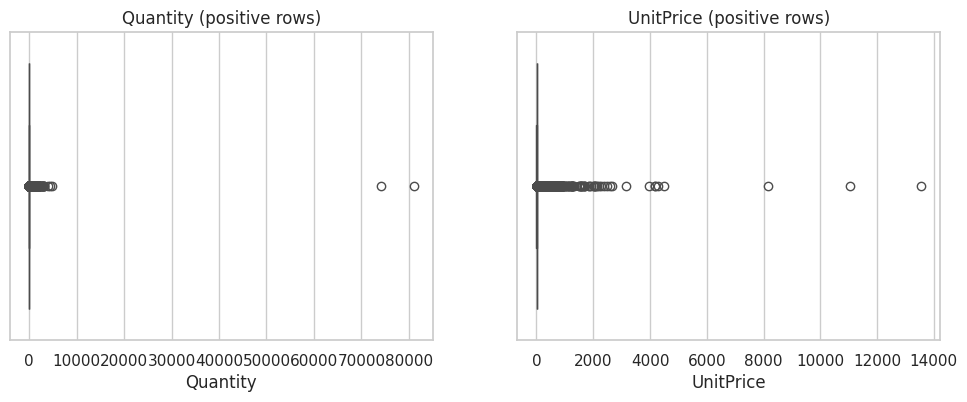

      Quantity  UnitPrice  Revenue
0.50      3.00       2.08     9.90
0.95     30.00       9.95    59.70
0.99    100.00      16.98   183.60
1.00    449.79     165.00   835.20


In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=tmp.Quantity, ax=ax[0]); ax[0].set_title("Quantity (positive rows)")
sns.boxplot(x=tmp.UnitPrice, ax=ax[1]); ax[1].set_title("UnitPrice (positive rows)")
plt.show()
print(tmp[["Quantity", "UnitPrice", "Revenue"]].quantile([.5, .95, .99, .999]))

In [35]:
clean = raw.copy()
log = [("Raw data", len(clean))]

clean = clean.dropna(subset=["CustomerID"])
log.append(("Drop missing CustomerID (can't build customer features)", len(clean)))

clean = clean.drop_duplicates()
log.append(("Drop exact duplicate rows", len(clean)))

clean = clean[~clean.InvoiceNo.astype(str).str.startswith("C")]
log.append(("Drop cancelled invoices", len(clean)))

clean = clean[(clean.Quantity > 0) & (clean.UnitPrice > 0)]
log.append(("Drop Quantity <= 0 or UnitPrice <= 0", len(clean)))

# keep real products only (5-digit codes); drops POST, D, M, BANK CHARGES etc.
clean = clean[clean.StockCode.astype(str).str.match(r"^\d{5}")]
log.append(("Drop non-product StockCodes (postage, fees, manual)", len(clean)))

clean["CustomerID"] = clean.CustomerID.astype(int)
clean["LineTotal"] = clean.Quantity * clean.UnitPrice

pd.DataFrame(log, columns=["Step", "Rows remaining"])

,Step,Rows remaining
0,Raw data,541909
1,Drop missing CustomerID (can't build customer ...,406829
2,Drop exact duplicate rows,401604
3,Drop cancelled invoices,392732
4,Drop Quantity <= 0 or UnitPrice <= 0,392692
5,"Drop non-product StockCodes (postage, fees, ma...",391150


In [36]:
snapshot = clean.InvoiceDate.max() + pd.Timedelta(days=1)

cust = clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum"),
    UniqueProducts=("StockCode", "nunique"),
)
print(cust.shape)
display(cust.describe().T)

(4334, 4)


,count,mean,std,min,25%,50%,75%,max
Recency,"4,334.00",92.70,100.18,1.00,18.00,51.00,143.00,374.00
Frequency,"4,334.00",4.25,7.63,1.00,1.00,2.00,5.00,206.00
Monetary,"4,334.00","2,015.97","8,903.67",3.75,304.24,662.57,"1,631.62","279,138.02"
UniqueProducts,"4,334.00",61.43,85.31,1.00,16.00,35.00,77.00,"1,785.00"


Skewness BEFORE log:
 Recency           1.24
Frequency        11.95
Monetary         19.58
UniqueProducts    6.92
dtype: float64

Skewness AFTER log1p:
 Recency          -0.38
Frequency         1.21
Monetary          0.40
UniqueProducts   -0.24
dtype: float64


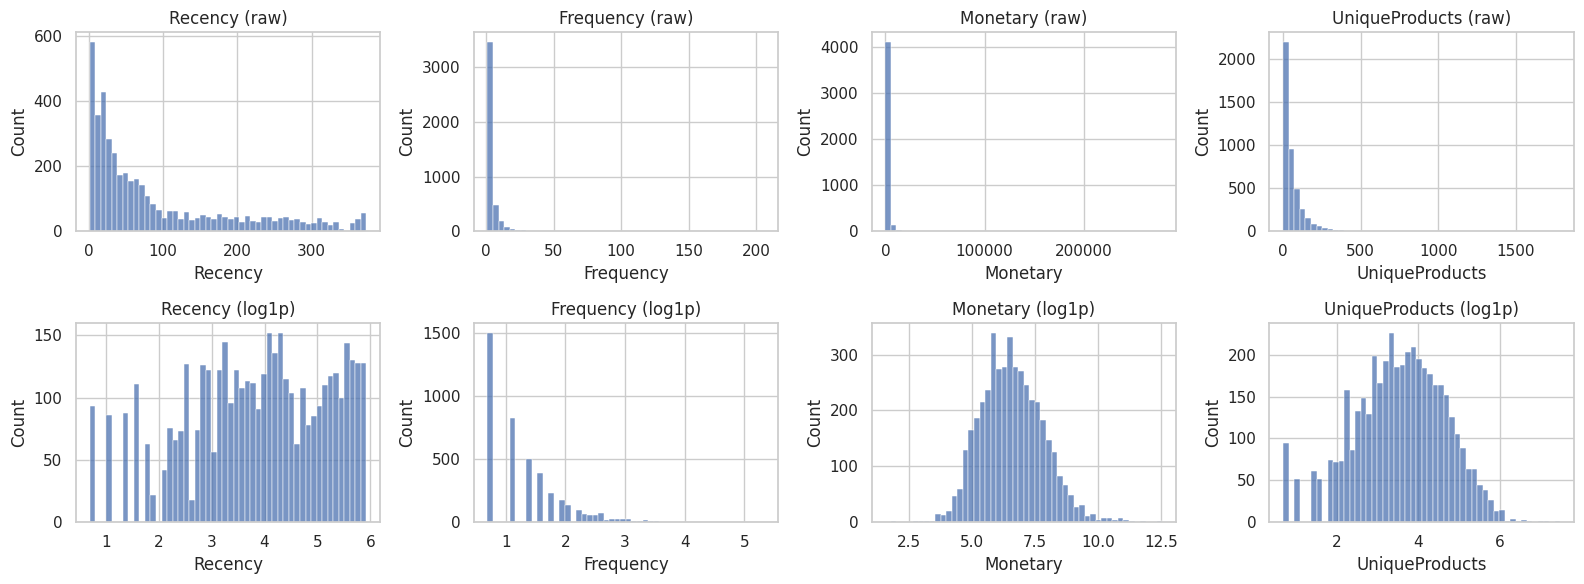

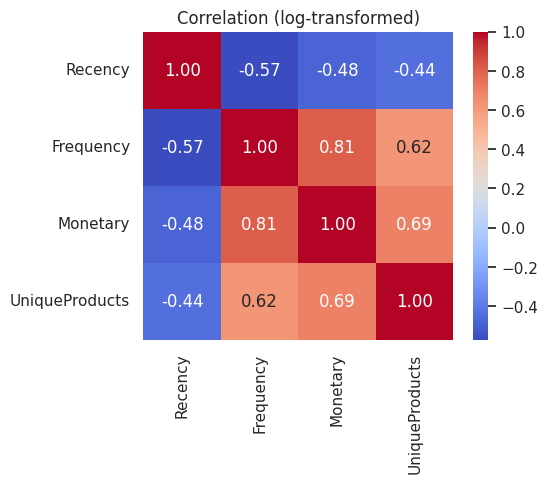

In [37]:
print("Skewness BEFORE log:\n", cust.skew().round(2))

cust_log = np.log1p(cust)
print("\nSkewness AFTER log1p:\n", cust_log.skew().round(2))

fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(cust.columns):
    sns.histplot(cust[c], bins=50, ax=ax[0, i]); ax[0, i].set_title(f"{c} (raw)")
    sns.histplot(cust_log[c], bins=50, ax=ax[1, i]); ax[1, i].set_title(f"{c} (log1p)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(cust_log.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation (log-transformed)")
plt.show()

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(cust_log)
X_df = pd.DataFrame(X, index=cust.index, columns=cust.columns)

display(X_df.describe().T.round(2))
print("Final clustering matrix:", X.shape)

cust.to_pickle("cust.pkl")
X_df.to_pickle("X_df.pkl")

,count,mean,std,min,25%,50%,75%,max
Recency,"4,334.00",0.00,1.00,-2.34,-0.66,0.09,0.85,1.56
Frequency,"4,334.00",-0.00,1.00,-0.95,-0.95,-0.36,0.66,5.85
Monetary,"4,334.00",0.00,1.00,-4.00,-0.68,-0.06,0.66,4.75
UniqueProducts,"4,334.00",0.00,1.00,-2.52,-0.63,0.03,0.71,3.48


Final clustering matrix: (4334, 4)


In [39]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

X = X_df.values
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("PCA variance explained:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

PCA variance explained: [0.707 0.152] | total: 0.859


,K,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,"9,125.82",0.40,0.95,"3,897.36"
1,3,"7,083.82",0.30,1.14,"3,134.09"
2,4,"6,141.43",0.28,1.20,"2,630.95"
3,5,"5,298.98",0.25,1.19,"2,458.42"
4,6,"4,810.49",0.23,1.23,"2,253.88"
5,7,"4,413.39",0.23,1.17,"2,111.64"
6,8,"4,107.29",0.22,1.20,"1,990.50"
7,9,"3,858.62",0.23,1.16,"1,888.30"
8,10,"3,641.09",0.23,1.17,"1,807.08"


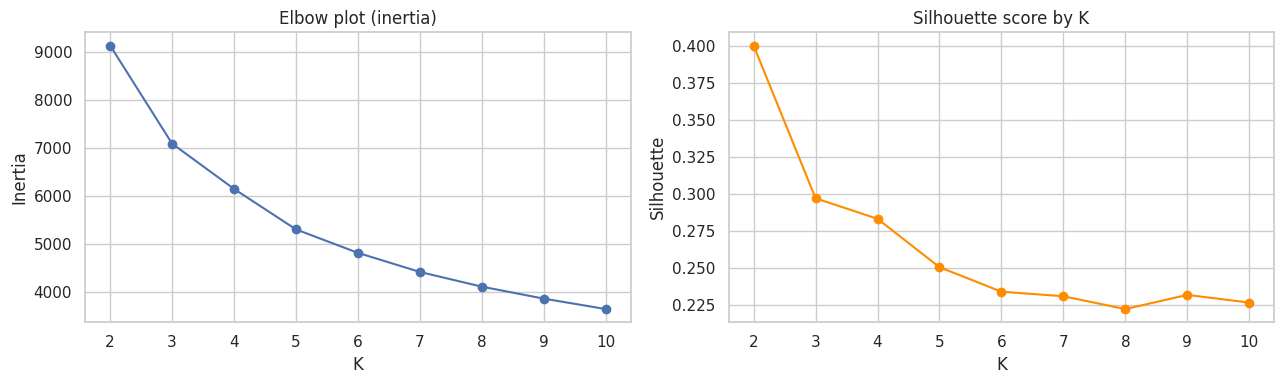

In [40]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    rows.append({
        "K": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
    })
kmeans_scan = pd.DataFrame(rows)
display(kmeans_scan.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(kmeans_scan.K, kmeans_scan.Inertia, marker="o")
ax[0].set_title("Elbow plot (inertia)"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia")
ax[1].plot(kmeans_scan.K, kmeans_scan.Silhouette, marker="o", color="darkorange")
ax[1].set_title("Silhouette score by K"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig("fig_kmeans_elbow_silhouette.png", dpi=200, bbox_inches="tight")
plt.show()

In [41]:
K_FINAL = 4   # <-- set this after reading the plots

t0 = time.perf_counter()
km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X)
km_runtime = time.perf_counter() - t0
km_labels = km_final.labels_

km_results = {
    "params": f"K={K_FINAL}, n_init=10",
    "n_clusters": K_FINAL,
    "sizes": dict(sorted(pd.Series(km_labels).value_counts().items())),
    "silhouette": silhouette_score(X, km_labels),
    "davies_bouldin": davies_bouldin_score(X, km_labels),
    "calinski_harabasz": calinski_harabasz_score(X, km_labels),
    "noise_pct": 0.0,
    "runtime": km_runtime,
}
for k_, v_ in km_results.items(): print(f"{k_:18}: {v_}")

params            : K=4, n_init=10
n_clusters        : 4
sizes             : {0: 821, 1: 1245, 2: 1448, 3: 820}
silhouette        : 0.2833031284913591
davies_bouldin    : 1.2029822418269345
calinski_harabasz : 2630.94509540589
noise_pct         : 0.0
runtime           : 0.06102237300001434


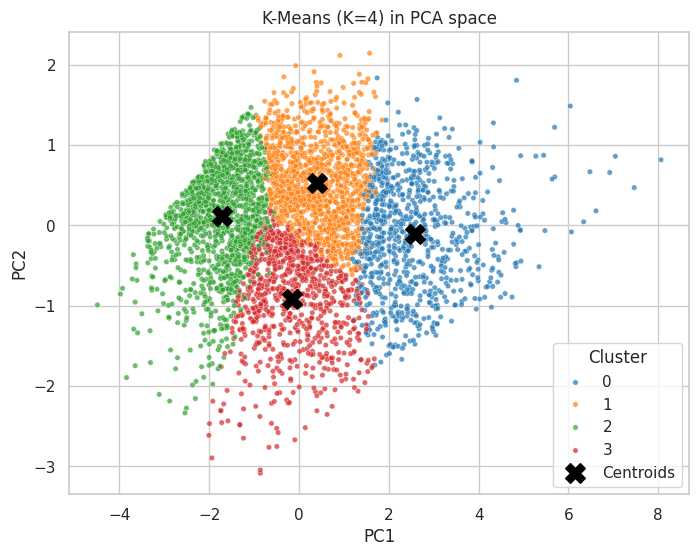

In [42]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=km_labels, palette="tab10", s=15, alpha=0.7)
centers_pca = pca.transform(km_final.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.title(f"K-Means (K={K_FINAL}) in PCA space")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="Cluster")
plt.savefig("fig_kmeans_pca.png", dpi=200, bbox_inches="tight")
plt.show()

,Customers,Recency,Frequency,Monetary,UniqueProducts,% of customers,% of revenue
Cluster,,,,,,,
0,821,14.30,12.60,"7,236.70",155.70,18.90,68.00
1,1245,85.80,3.50,"1,507.10",70.50,28.70,21.50
2,1448,184.30,1.30,304.30,15.70,33.40,5.00
3,820,20.00,2.20,584.00,34.10,18.90,5.50


,Recency,Frequency,Monetary,UniqueProducts
Cluster,,,,
0,10.00,9.00,"3,353.00",119.00
1,65.00,3.00,"1,096.30",58.00
2,183.50,1.00,250.60,13.00
3,17.50,2.00,464.00,28.00


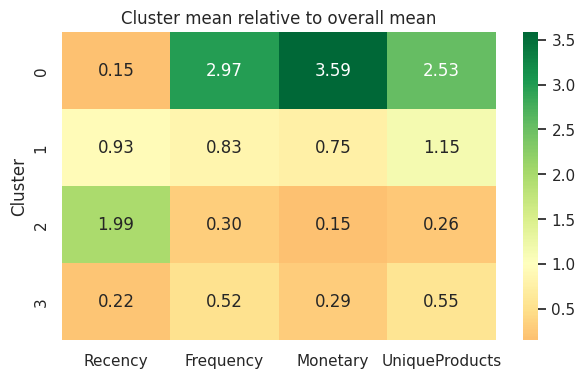

In [43]:
feats = ["Recency", "Frequency", "Monetary", "UniqueProducts"]
prof = cust.copy()
prof["Cluster"] = km_labels

summary = prof.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    UniqueProducts=("UniqueProducts", "mean"),
)
summary["% of customers"] = summary.Customers / len(prof) * 100
summary["% of revenue"] = prof.groupby("Cluster").Monetary.sum() / prof.Monetary.sum() * 100
display(summary.round(1))
display(prof.groupby("Cluster")[feats].median().round(1))

# Relative profile: cluster mean / overall mean (1.0 = average)
rel = summary[feats] / cust[feats].mean()
plt.figure(figsize=(7, 4))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn", center=1)
plt.title("Cluster mean relative to overall mean")
plt.savefig("fig_kmeans_profile.png", dpi=200, bbox_inches="tight")
plt.show()

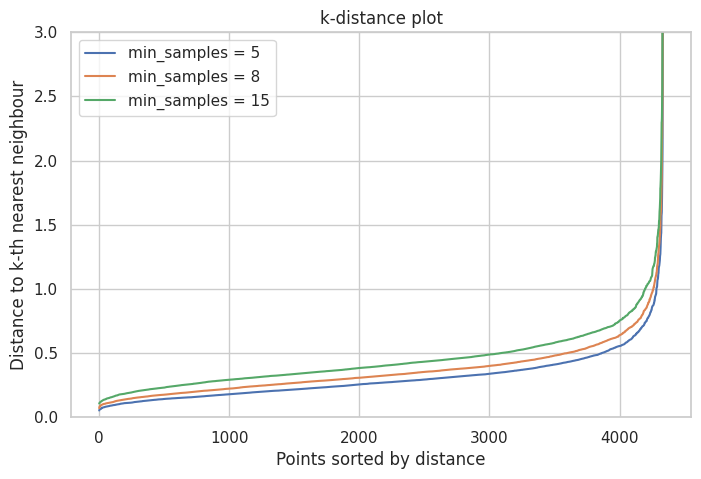

In [44]:
plt.figure(figsize=(8, 5))
for ms in [5, 8, 15]:
    nn = NearestNeighbors(n_neighbors=ms).fit(X)
    d, _ = nn.kneighbors(X)
    plt.plot(np.sort(d[:, -1]), label=f"min_samples = {ms}")
plt.ylim(0, 3)
plt.xlabel("Points sorted by distance"); plt.ylabel("Distance to k-th nearest neighbour")
plt.title("k-distance plot"); plt.legend()
plt.savefig("fig_dbscan_kdistance.png", dpi=200, bbox_inches="tight")
plt.show()

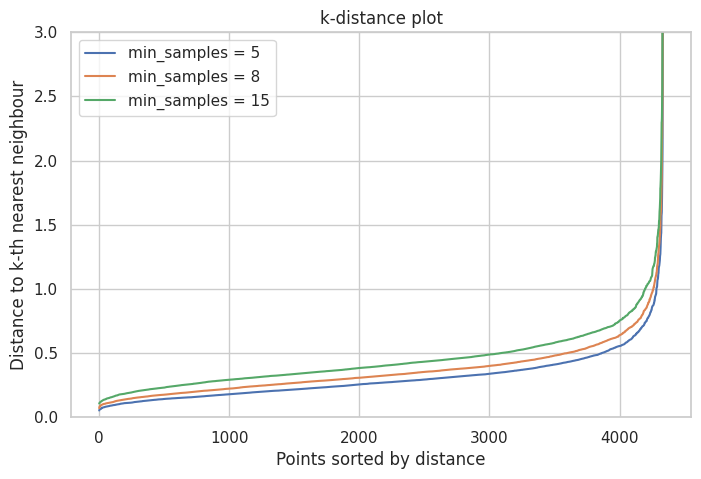

In [45]:
plt.figure(figsize=(8, 5))
for ms in [5, 8, 15]:
    nn = NearestNeighbors(n_neighbors=ms).fit(X)
    d, _ = nn.kneighbors(X)
    plt.plot(np.sort(d[:, -1]), label=f"min_samples = {ms}")
plt.ylim(0, 3)
plt.xlabel("Points sorted by distance"); plt.ylabel("Distance to k-th nearest neighbour")
plt.title("k-distance plot"); plt.legend()
plt.savefig("fig_dbscan_kdistance.png", dpi=200, bbox_inches="tight")
plt.show()

In [46]:
grid = []
for ms in [5, 8, 10, 15]:
    for eps in np.round(np.arange(0.2, 1.05, 0.1), 2):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = lab != -1
        n_cl = len(set(lab[mask]))
        grid.append({
            "eps": eps, "min_samples": ms, "clusters": n_cl,
            "noise_%": (~mask).mean() * 100,
            "silhouette (non-noise)": silhouette_score(X[mask], lab[mask]) if n_cl >= 2 else np.nan,
        })
grid_df = pd.DataFrame(grid)
display(grid_df.round(3).to_string())

'    eps  min_samples  clusters  noise_%  silhouette (non-noise)\n0  0.20            5        50    60.64                   -0.19\n1  0.30            5        29    28.57                   -0.18\n2  0.40            5        11    13.13                   -0.04\n3  0.50            5         4     5.98                    0.18\n4  0.60            5         1     3.37                     NaN\n5  0.70            5         2     2.01                    0.19\n6  0.80            5         1     1.36                     NaN\n7  0.90            5         1     0.88                     NaN\n8  1.00            5         2     0.58                    0.55\n9  0.20            8        22    73.23                   -0.12\n10 0.30            8        16    41.26                   -0.06\n11 0.40            8         4    18.50                    0.11\n12 0.50            8         4     8.47                    0.16\n13 0.60            8         2     4.50                    0.18\n14 0.70            8    

In [47]:
EPS_FINAL = 0.5          # <-- set from the k-distance plot and grid
MIN_SAMPLES_FINAL = 8    # <-- set from the grid

t0 = time.perf_counter()
db = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL).fit(X)
db_runtime = time.perf_counter() - t0
db_labels = db.labels_

mask = db_labels != -1
n_clusters = len(set(db_labels[mask]))
noise_n = (~mask).sum()
print("Clusters:", n_clusters)
print("Cluster sizes:\n", pd.Series(db_labels[mask]).value_counts().sort_index())
print(f"Noise points: {noise_n} ({noise_n / len(X) * 100:.2f}%)")
print(f"Records retained for metrics: {mask.sum()} ({mask.mean() * 100:.2f}%)")

# Metrics on NON-NOISE points only (state this in your report)
if n_clusters >= 2:
    db_sil = silhouette_score(X[mask], db_labels[mask])
    db_dbi = davies_bouldin_score(X[mask], db_labels[mask])
    db_chi = calinski_harabasz_score(X[mask], db_labels[mask])
else:
    db_sil = db_dbi = db_chi = "N/A"

db_results = {
    "params": f"eps={EPS_FINAL}, min_samples={MIN_SAMPLES_FINAL}",
    "n_clusters": n_clusters,
    "sizes": dict(sorted(pd.Series(db_labels[mask]).value_counts().items())),
    "silhouette": db_sil, "davies_bouldin": db_dbi, "calinski_harabasz": db_chi,
    "noise_pct": noise_n / len(X) * 100,
    "retained_pct": mask.mean() * 100,
    "runtime": db_runtime,
}
for k_, v_ in db_results.items(): print(f"{k_:18}: {v_}")

Clusters: 4
Cluster sizes:
 0    2519
1    1432
2       9
3       7
Name: count, dtype: int64
Noise points: 367 (8.47%)
Records retained for metrics: 3967 (91.53%)
params            : eps=0.5, min_samples=8
n_clusters        : 4
sizes             : {0: 2519, 1: 1432, 2: 9, 3: 7}
silhouette        : 0.1636295420720377
davies_bouldin    : 0.8410867598098519
calinski_harabasz : 820.3551462266103
noise_pct         : 8.46792801107522
retained_pct      : 91.53207198892478
runtime           : 0.08500987200022792


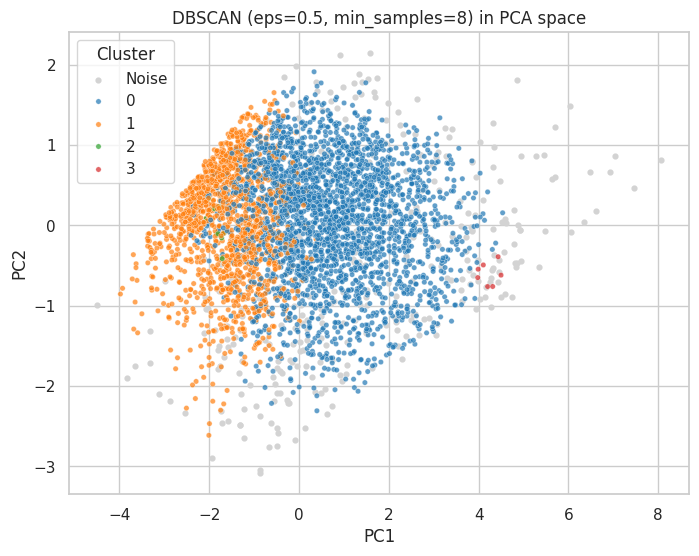

In [48]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[~mask, 0], X_pca[~mask, 1], c="lightgrey", s=12, label="Noise")
sns.scatterplot(x=X_pca[mask, 0], y=X_pca[mask, 1], hue=db_labels[mask], palette="tab10", s=15, alpha=0.7)
plt.title(f"DBSCAN (eps={EPS_FINAL}, min_samples={MIN_SAMPLES_FINAL}) in PCA space")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="Cluster")
plt.savefig("fig_dbscan_pca.png", dpi=200, bbox_inches="tight")
plt.show()

In [49]:
prof_db = cust.copy()
prof_db["DBSCAN"] = db_labels
display(prof_db.groupby("DBSCAN")[feats].agg(["count", "mean"]).round(1))

cust["KMeans"] = km_labels
cust["DBSCAN"] = db_labels
cust.to_pickle("cust_labeled.pkl")

Recency        Frequency       Monetary           UniqueProducts       
         count   mean     count  mean    count      mean          count   mean
DBSCAN                                                                        
-1         367  49.30       367 12.80      367 10,950.10            367 104.50
 0        2519  60.00      2519  4.80     2519  1,653.30           2519  78.00
 1        1432 161.10      1432  1.00     1432    327.00           1432  21.00
 2           9 210.40         9  2.10        9    736.90              9   1.20
 3           7   1.60         7 23.90        7 11,287.90              7 160.00

In [50]:
def avg_runtime(fn, repeats=10):
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return np.mean(ts), np.std(ts)

km_t = avg_runtime(lambda: KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X))
db_t = avg_runtime(lambda: DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL).fit(X))

fmt_sizes = lambda d: ", ".join(f"{int(v):,}" for v in d.values())
f3 = lambda v: v if isinstance(v, str) else f"{v:,.3f}"

comparison = pd.DataFrame({
    "K-Means": [
        km_results["params"], km_results["n_clusters"], fmt_sizes(km_results["sizes"]),
        f3(km_results["silhouette"]), f3(km_results["davies_bouldin"]), f3(km_results["calinski_harabasz"]),
        "0.00", f"{km_t[0]:.4f} ± {km_t[1]:.4f}"],
    "DBSCAN": [
        db_results["params"], f'{db_results["n_clusters"]} (+ noise)',
        fmt_sizes(db_results["sizes"]) + f" | noise: {noise_n}",
        f3(db_results["silhouette"]), f3(db_results["davies_bouldin"]), f3(db_results["calinski_harabasz"]),
        f'{db_results["noise_pct"]:.2f}', f"{db_t[0]:.4f} ± {db_t[1]:.4f}"],
}, index=["Selected parameters", "Number of clusters", "Cluster sizes", "Silhouette Score",
          "Davies–Bouldin Index", "Calinski–Harabasz Index", "Noise points (%)",
          "Runtime (s, mean ± sd, 10 runs)"])
display(comparison)
comparison.to_csv("comparison_table.csv")

,K-Means,DBSCAN
Selected parameters,"K=4, n_init=10","eps=0.5, min_samples=8"
Number of clusters,4,4 (+ noise)
Cluster sizes,"821, 1,245, 1,448, 820","2,519, 1,432, 9, 7 | noise: 367"
Silhouette Score,0.283,0.164
Davies–Bouldin Index,1.203,0.841
Calinski–Harabasz Index,"2,630.945",820.355
Noise points (%),0.00,8.47
"Runtime (s, mean ± sd, 10 runs)",0.0928 ± 0.0057,0.1274 ± 0.0049


In [51]:
same = pd.DataFrame({
    "K-Means (all 4,334)": [silhouette_score(X, km_labels), davies_bouldin_score(X, km_labels),
                            calinski_harabasz_score(X, km_labels), 100.0],
    "K-Means (same 3,967 points as DBSCAN)": [silhouette_score(X[mask], km_labels[mask]),
                            davies_bouldin_score(X[mask], km_labels[mask]),
                            calinski_harabasz_score(X[mask], km_labels[mask]), mask.mean() * 100],
    "DBSCAN (3,967 non-noise points)": [db_sil, db_dbi, db_chi, mask.mean() * 100],
}, index=["Silhouette", "Davies–Bouldin", "Calinski–Harabasz", "% of records used"])
display(same.round(3))

,"K-Means (all 4,334)","K-Means (same 3,967 points as DBSCAN)","DBSCAN (3,967 non-noise points)"
Silhouette,0.28,0.30,0.16
Davies–Bouldin,1.20,1.18,0.84
Calinski–Harabasz,"2,630.95","2,699.43",820.36
% of records used,100.00,91.53,91.53


In [52]:
from sklearn.metrics import adjusted_rand_score

# (a) K-Means: 10 random seeds vs the final model
km_seed = [adjusted_rand_score(km_labels,
           KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit_predict(X)) for s in range(10)]

# (b) 80% subsamples: re-cluster and compare with full-data labels on the same points
rng = np.random.RandomState(RANDOM_STATE)
km_sub, db_sub = [], []
for _ in range(10):
    idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    km_sub.append(adjusted_rand_score(km_labels[idx],
                  KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit_predict(X[idx])))
    db_sub.append(adjusted_rand_score(db_labels[idx],
                  DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL).fit_predict(X[idx])))

print(f"K-Means ARI across seeds      : {np.mean(km_seed):.3f} (min {np.min(km_seed):.3f})")
print(f"K-Means ARI on 80% subsamples : {np.mean(km_sub):.3f} ± {np.std(km_sub):.3f}")
print(f"DBSCAN  ARI on 80% subsamples : {np.mean(db_sub):.3f} ± {np.std(db_sub):.3f}")

# (c) DBSCAN sensitivity to eps
rows = []
for e in [0.40, 0.45, 0.50, 0.55, 0.60]:
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES_FINAL).fit_predict(X)
    rows.append({"eps": e, "clusters": len(set(lab) - {-1}), "noise_%": (lab == -1).mean() * 100,
                 "ARI vs eps=0.5": adjusted_rand_score(db_labels, lab)})
display(pd.DataFrame(rows).round(3))

K-Means ARI across seeds      : 0.920 (min 0.866)
K-Means ARI on 80% subsamples : 0.622 ± 0.301
DBSCAN  ARI on 80% subsamples : 0.951 ± 0.006


,eps,clusters,noise_%,ARI vs eps=0.5
0,0.40,4,18.50,0.53
1,0.45,4,12.74,0.89
2,0.50,4,8.47,1.00
3,0.55,3,6.44,0.95
4,0.60,2,4.50,0.14


In [53]:
# Tenure (days since first purchase), to check whether a cluster really is "new customers"
first = clean.groupby("CustomerID").InvoiceDate.min()
cust["TenureDays"] = (snapshot - first.reindex(cust.index)).dt.days
display(cust.groupby("KMeans")["TenureDays"].agg(["mean", "median"]).round(1))

# How much revenue does DBSCAN call "noise"?
noise_rev = cust.loc[cust.DBSCAN == -1, "Monetary"].sum() / cust.Monetary.sum() * 100
print(f"DBSCAN noise = {noise_n / len(cust) * 100:.1f}% of customers but {noise_rev:.1f}% of revenue")

# Where do K-Means segments land in DBSCAN?
display(pd.crosstab(cust.KMeans, cust.DBSCAN, margins=True))

,mean,median
KMeans,,
0,306.40,339.00
1,252.40,269.00
2,205.70,218.00
3,126.90,71.00


DBSCAN noise = 8.5% of customers but 46.0% of revenue


DBSCAN,-1,0,1,2,3,All
KMeans,,,,,,
0,154,660,0,0,7,821
1,60,1100,85,0,0,1245
2,59,269,1111,9,0,1448
3,94,490,236,0,0,820
All,367,2519,1432,9,7,4334


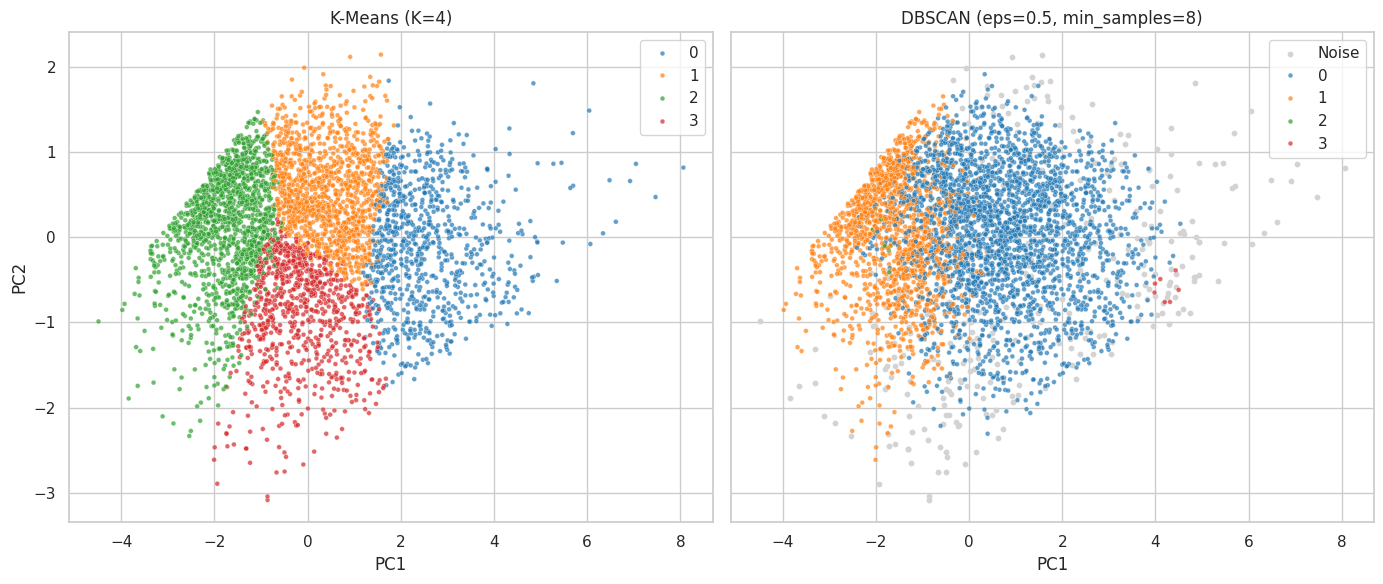

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=km_labels, palette="tab10", s=12, alpha=.7, ax=ax[0])
ax[0].set_title(f"K-Means (K={K_FINAL})")
ax[1].scatter(X_pca[~mask, 0], X_pca[~mask, 1], c="lightgrey", s=10, label="Noise")
sns.scatterplot(x=X_pca[mask, 0], y=X_pca[mask, 1], hue=db_labels[mask], palette="tab10", s=12, alpha=.7, ax=ax[1])
ax[1].set_title(f"DBSCAN (eps={EPS_FINAL}, min_samples={MIN_SAMPLES_FINAL})")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout()
plt.savefig("fig_side_by_side.png", dpi=200, bbox_inches="tight")
plt.show()